1. Mengambil data BTC-USD dari tahun 2021-2024...
YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed

2. Menghitung Prediksi Risiko (GARCH)...
3. Memulai Simulasi Auto-Trading...
📊 LAPORAN KINERJA BOT (2021 - 2024)
Modal Awal     : $10,000.00
Modal Akhir    : $9,045.67
Total Profit   : -9.54%
Total Trade    : 86 kali transaksi
Win Rate       : 38.37% (Menang 33, Kalah 53)


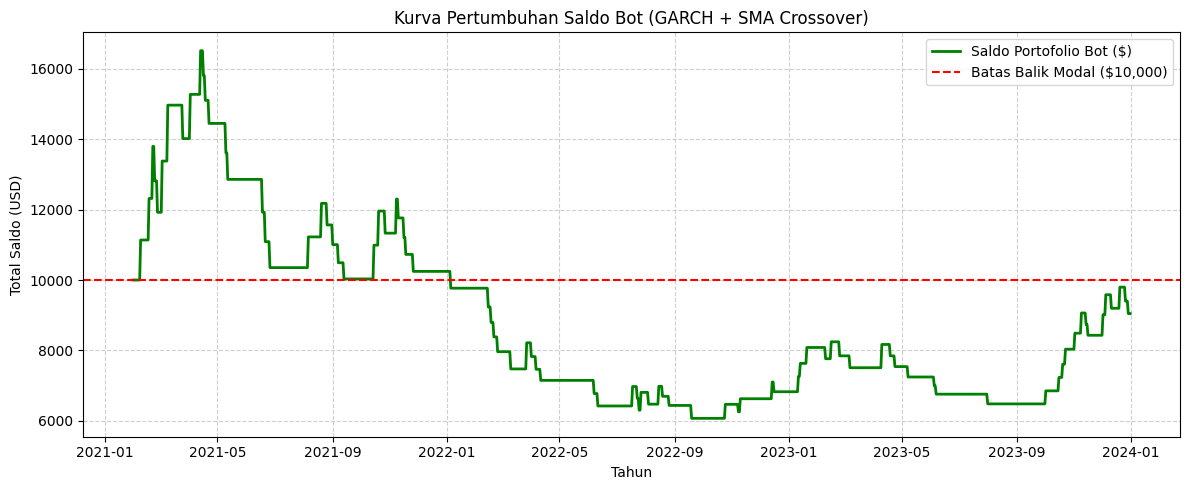

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. PERSIAPAN DATA & INDIKATOR
# ==========================================
print("1. Mengambil data BTC-USD dari tahun 2021-2024...")
df = yf.download('BTC-USD', start='2021-01-01', end='2024-01-01')

# Merapikan struktur kolom jika formatnya MultiIndex
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.droplevel(1)

# Membuat Sinyal Arah (SMA 10 dan SMA 30)
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_30'] = df['Close'].rolling(window=30).mean()

# Menghitung Return Harian & Model GARCH
df['Return'] = df['Close'].pct_change() * 100
df = df.dropna()

print("2. Menghitung Prediksi Risiko (GARCH)...")
model = arch_model(df['Return'], vol='Garch', p=1, q=1, mean='Constant')
model_fit = model.fit(disp='off')

# PENTING: Kita harus men-shift volatilitas GARCH 1 hari ke depan.
# Kenapa? Karena saat kita trading HARI INI, kita hanya tahu data volatilitas KEMARIN.
# Ini untuk mencegah bot "mengintip masa depan" (Look-ahead bias).
df['GARCH_Vol'] = model_fit.conditional_volatility.shift(1)
df = df.dropna()

# ==========================================
# 3. MESIN SIMULASI BACKTESTING
# ==========================================
print("3. Memulai Simulasi Auto-Trading...")

modal_awal = 10000.0  # Modal awal $10,000
modal_sekarang = modal_awal
posisi = 0            # 0 = Tidak pegang koin, 1 = Sedang pegang koin
harga_beli = 0
stop_loss = 0
take_profit = 0

catatan_saldo = []    # Menyimpan jejak saldo setiap hari
total_menang = 0
total_kalah = 0

# Looping mesin waktu (Mengecek hari demi hari)
for tanggal, hari_ini in df.iterrows():
    
    # KONDISI 1: JIKA KITA SEDANG TIDAK PEGANG KOIN (Cari Peluang Beli)
    if posisi == 0:
        # Cek Sinyal: Apakah SMA 10 (Cepat) berada di atas SMA 30 (Lambat)?
        if hari_ini['SMA_10'] > hari_ini['SMA_30']:
            # EKSEKUSI BUY!
            posisi = 1
            harga_beli = hari_ini['Close']
            
            # Memasang Jaring GARCH (Risiko Dinamis)
            # Volatilitas dibagi 100 agar jadi desimal (misal 5% jadi 0.05)
            vol_desimal = hari_ini['GARCH_Vol'] / 100 
            
            # Rumus SL dan TP Dinamis
            stop_loss = harga_beli * (1 - (vol_desimal * 1.5))
            take_profit = harga_beli * (1 + (vol_desimal * 2.5))
            
    # KONDISI 2: JIKA KITA SEDANG PEGANG KOIN (Tunggu Kena SL atau TP)
    elif posisi == 1:
        # Cek apakah harga hari ini menyentuh TAKE PROFIT
        if hari_ini['High'] >= take_profit:
            keuntungan = (take_profit - harga_beli) / harga_beli
            modal_sekarang = modal_sekarang * (1 + keuntungan)
            posisi = 0 # Jual koin
            total_menang += 1
            
        # Cek apakah harga hari ini menyentuh STOP LOSS
        elif hari_ini['Low'] <= stop_loss:
            kerugian = (harga_beli - stop_loss) / harga_beli
            modal_sekarang = modal_sekarang * (1 - kerugian)
            posisi = 0 # Jual rugi (Cut loss)
            total_kalah += 1
            
        # Jika hari ini tidak kena SL maupun TP, ya dibiarkan saja (Hold)
            
    # Mencatat saldo harian ke buku kas
    catatan_saldo.append(modal_sekarang)

# Memasukkan catatan saldo ke tabel
df['Saldo_Bot'] = catatan_saldo

# ==========================================
# 4. LAPORAN HASIL & VISUALISASI
# ==========================================
total_trade = total_menang + total_kalah
win_rate = (total_menang / total_trade) * 100 if total_trade > 0 else 0
roi = ((modal_sekarang - modal_awal) / modal_awal) * 100

print("="*50)
print("📊 LAPORAN KINERJA BOT (2021 - 2024)")
print("="*50)
print(f"Modal Awal     : ${modal_awal:,.2f}")
print(f"Modal Akhir    : ${modal_sekarang:,.2f}")
print(f"Total Profit   : {roi:.2f}%")
print(f"Total Trade    : {total_trade} kali transaksi")
print(f"Win Rate       : {win_rate:.2f}% (Menang {total_menang}, Kalah {total_kalah})")
print("="*50)

# Visualisasi Kinerja Saldo (Equity Curve)
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Saldo_Bot'], color='green', linewidth=2, label='Saldo Portofolio Bot ($)')
plt.axhline(modal_awal, color='red', linestyle='--', label='Batas Balik Modal ($10,000)')
plt.title('Kurva Pertumbuhan Saldo Bot (GARCH + SMA Crossover)')
plt.xlabel('Tahun')
plt.ylabel('Total Saldo (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed

Mengambil data BTC-USD (2020 - 2024)...
Menganalisis GARCH Volatilitas...

🔍 FASE 1: OPTIMASI DI DATA IN-SAMPLE (2020-2022)
Menguji EMA 5 & 20 -> ROI: 228.44%
Menguji EMA 5 & 30 -> ROI: 268.45%
Menguji EMA 5 & 50 -> ROI: 216.02%
Menguji EMA 10 & 20 -> ROI: 361.94%
Menguji EMA 10 & 30 -> ROI: 266.61%
Menguji EMA 10 & 50 -> ROI: 244.76%
Menguji EMA 15 & 20 -> ROI: 269.77%
Menguji EMA 15 & 30 -> ROI: 159.85%
Menguji EMA 15 & 50 -> ROI: 292.26%

🌟 HASIL OPTIMASI: Kombinasi terbaik adalah EMA 10 & 20 (Profit: 361.94%)
Kita kunci parameter ini untuk ujian di masa depan!

🚀 FASE 2: PENGUJIAN OUT-OF-SAMPLE (2023)
Menggunakan data yang belum pernah dilihat bot (Tahun 2023)...
Hasil Ujian Masa Depan (OOS ROI): 73.88%
✅ KESIMPULAN: Strategi Anda ROBUST (Kuat)! Bot berhasil mencetak profit di data baru yang tidak ia hafal.


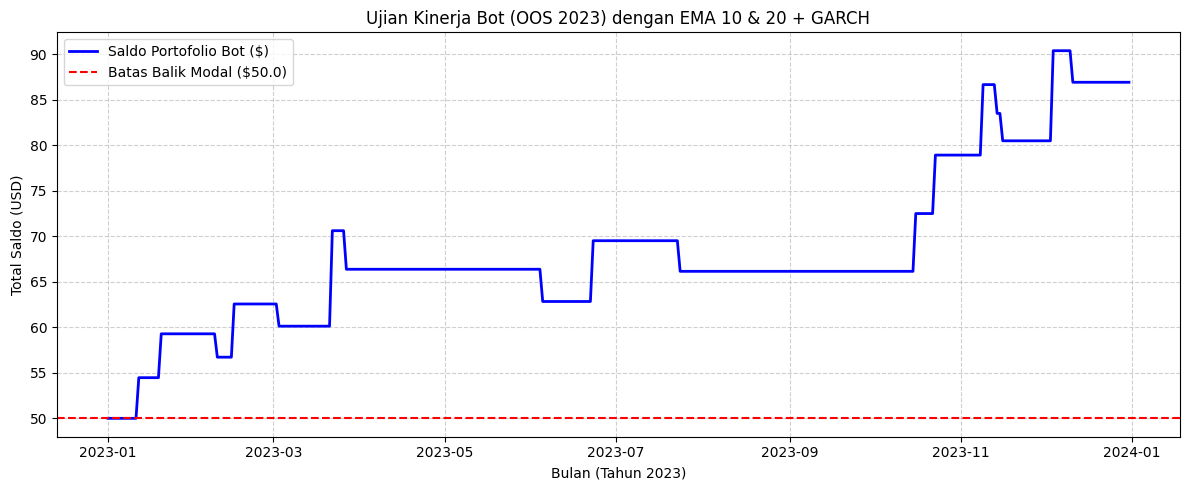

In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. FUNGSI MESIN BACKTEST (Dapat Dipakai Berulang)
# ==========================================
def run_backtest(df_input, ema_fast, ema_slow, tp_mult=4.0, sl_mult=1.5):
    """Menjalankan simulasi trading dengan parameter tertentu dan mengembalikan ROI serta histori saldo."""
    df = df_input.copy()
    
    # Membuat Indikator EMA sesuai parameter
    df['EMA_Fast'] = df['Close'].ewm(span=ema_fast, adjust=False).mean()
    df['EMA_Slow'] = df['Close'].ewm(span=ema_slow, adjust=False).mean()
    
    modal_awal = 50.0
    modal_sekarang = modal_awal
    posisi = 0
    harga_beli = stop_loss = take_profit = 0
    catatan_saldo = []
    
    for tanggal, hari_ini in df.iterrows():
        if posisi == 0:
            if hari_ini['EMA_Fast'] > hari_ini['EMA_Slow']:
                posisi = 1
                harga_beli = hari_ini['Close']
                vol_desimal = hari_ini['GARCH_Vol'] / 100 
                stop_loss = harga_beli * (1 - (vol_desimal * sl_mult))
                take_profit = harga_beli * (1 + (vol_desimal * tp_mult))
        elif posisi == 1:
            if hari_ini['High'] >= take_profit:
                modal_sekarang *= (1 + (take_profit - harga_beli) / harga_beli)
                posisi = 0
            elif hari_ini['Low'] <= stop_loss:
                modal_sekarang *= (1 - (harga_beli - stop_loss) / harga_beli)
                posisi = 0
                
        catatan_saldo.append(modal_sekarang)
        
    df['Saldo_Bot'] = catatan_saldo
    roi = ((modal_sekarang - modal_awal) / modal_awal) * 100
    return roi, df

# ==========================================
# 2. PERSIAPAN DATA (2020 - 2024)
# ==========================================
print("Mengambil data BTC-USD (2020 - 2024)...")
df_full = yf.download('BTC-USD', start='2020-01-01', end='2024-01-01')
if isinstance(df_full.columns, pd.MultiIndex):
    df_full.columns = df_full.columns.droplevel(1)

# Menghitung GARCH untuk seluruh data terlebih dahulu (agar efisien)
df_full['Return'] = df_full['Close'].pct_change() * 100
df_full = df_full.dropna()

print("Menganalisis GARCH Volatilitas...")
model = arch_model(df_full['Return'], vol='Garch', p=1, q=1, mean='Constant')
model_fit = model.fit(disp='off')
df_full['GARCH_Vol'] = model_fit.conditional_volatility.shift(1)
df_full = df_full.dropna()

# ==========================================
# 3. MEMBAGI DATA (IN-SAMPLE & OUT-OF-SAMPLE)
# ==========================================
# IN-SAMPLE: 1 Januari 2020 s/d 31 Desember 2022 (3 Tahun untuk Belajar)
df_in_sample = df_full.loc['2020-01-01':'2022-12-31']

# OUT-OF-SAMPLE: 1 Januari 2023 s/d Akhir 2023 (1 Tahun Unseen Data untuk Ujian)
df_out_of_sample = df_full.loc['2023-01-01':'2024-01-01']

print("\n" + "="*50)
print("🔍 FASE 1: OPTIMASI DI DATA IN-SAMPLE (2020-2022)")
print("="*50)

# Kita uji beberapa kombinasi EMA (Grid Search Sederhana)
kombinasi_ema_fast = [5, 10, 15]
kombinasi_ema_slow = [20, 30, 50]

best_roi = -999
best_params = (0, 0)

# Komputer akan mencoba semua kemungkinan dari daftar di atas
for fast in kombinasi_ema_fast:
    for slow in kombinasi_ema_slow:
        if fast >= slow: continue # Abaikan jika EMA cepat lebih besar dari lambat
        
        roi, _ = run_backtest(df_in_sample, ema_fast=fast, ema_slow=slow)
        print(f"Menguji EMA {fast} & {slow} -> ROI: {roi:.2f}%")
        
        # Simpan jika hasilnya lebih baik dari yang sebelumnya
        if roi > best_roi:
            best_roi = roi
            best_params = (fast, slow)

print(f"\n🌟 HASIL OPTIMASI: Kombinasi terbaik adalah EMA {best_params[0]} & {best_params[1]} (Profit: {best_roi:.2f}%)")
print("Kita kunci parameter ini untuk ujian di masa depan!")

# ==========================================
# 4. UJIAN DI DATA OUT-OF-SAMPLE (Masa Depan)
# ==========================================
print("\n" + "="*50)
print("🚀 FASE 2: PENGUJIAN OUT-OF-SAMPLE (2023)")
print("="*50)
print("Menggunakan data yang belum pernah dilihat bot (Tahun 2023)...")

# Kita jalankan backtest menggunakan Parameter Terbaik (best_params) ke data Out-of-Sample
final_roi, df_result = run_backtest(df_out_of_sample, ema_fast=best_params[0], ema_slow=best_params[1])

print(f"Hasil Ujian Masa Depan (OOS ROI): {final_roi:.2f}%")

if final_roi > 0:
    print("✅ KESIMPULAN: Strategi Anda ROBUST (Kuat)! Bot berhasil mencetak profit di data baru yang tidak ia hafal.")
else:
    print("❌ KESIMPULAN: Strategi OVERFITTING! Parameter ini hebat di 2020-2022, tapi hancur di 2023. Jangan pakai uang asli!")

# --- PERBAIKAN VISUALISASI ---
modal_awal_grafik = 50.0  # Sesuaikan dengan angka modal yang Anda ubah di dalam fungsi

plt.figure(figsize=(12, 5))
plt.plot(df_result.index, df_result['Saldo_Bot'], color='blue', linewidth=2, label='Saldo Portofolio Bot ($)')

# Menggunakan variabel dinamis, bukan angka 10000 statis
plt.axhline(modal_awal_grafik, color='red', linestyle='--', label=f'Batas Balik Modal (${modal_awal_grafik})')

plt.title(f'Ujian Kinerja Bot (OOS 2023) dengan EMA {best_params[0]} & {best_params[1]} + GARCH')
plt.xlabel('Bulan (Tahun 2023)')
plt.ylabel('Total Saldo (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Mendownload Data BTC-USD (1 Jam, Max 730 Hari)...


[*********************100%***********************]  1 of 1 completed


Membangun Fitur untuk AI (Feature Engineering)...
Melatih Model GARCH untuk fitur volatilitas...

Melatih Otak AI (Random Forest Classifier)...

📊 FITUR TERPENTING MENURUT AI:
- Ret_1H: 16.18%
- Ret_3H: 13.46%
- Ret_12H: 13.56%
- RSI_14: 15.23%
- Dist_EMA9: 11.69%
- Dist_EMA21: 16.39%
- GARCH_Vol: 13.49%

Mengeksekusi AI ke Data Ujian (Masa Depan)...

🚀 FASE UJIAN: Live Trading AI (Minimal Keyakinan 60.0%)
Modal Awal          : $50.00
Saldo Akhir Ujian   : $36.05
Net Profit (ROI)    : -27.90%
Maximum Drawdown    : -27.90%
Total Eksekusi AI   : 22 kali (Lebih selektif!)


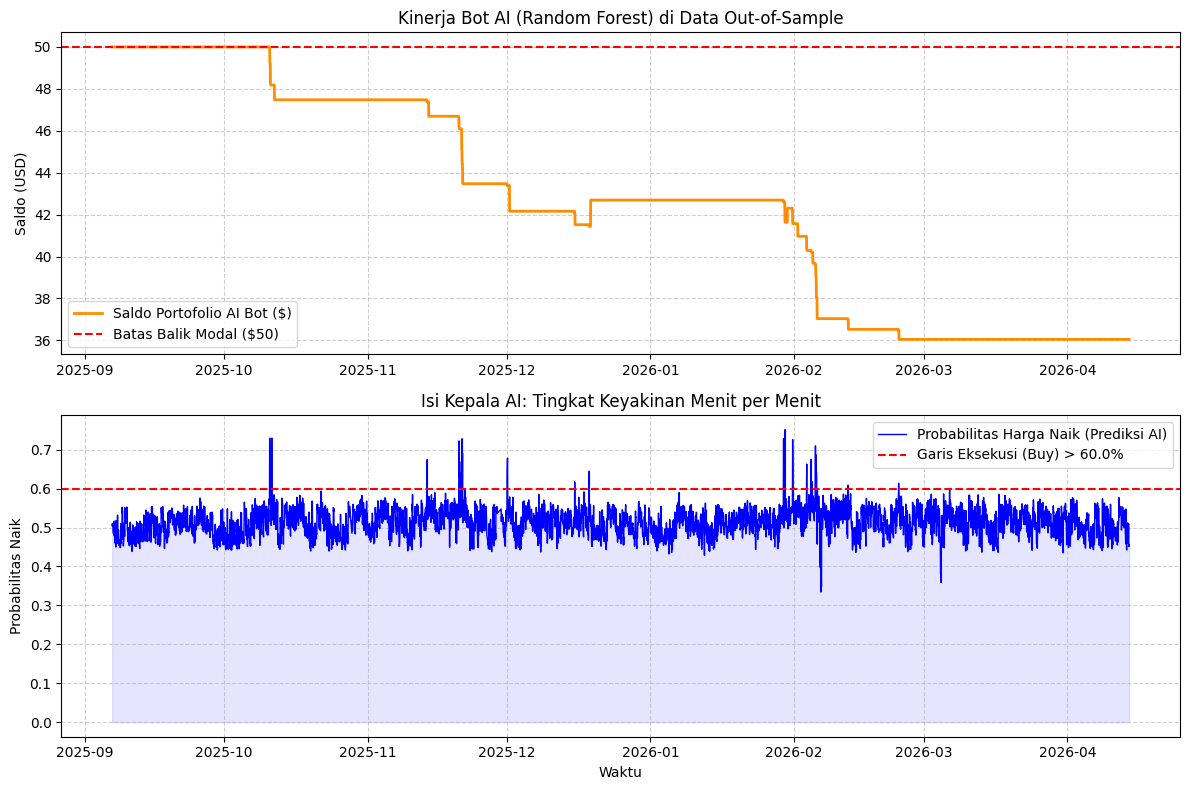

In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. FUNGSI PERSIAPAN DATA & FITUR MACHINE LEARNING
# ==========================================
def calculate_rsi(data, window=14):
    delta = data.diff()
    gain = delta.where(delta > 0, 0).ewm(alpha=1/window, adjust=False).mean()
    loss = (-delta.where(delta < 0, 0)).ewm(alpha=1/window, adjust=False).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

def prepare_ml_data(df):
    """Membuat Indikator yang akan dipelajari oleh AI (Features)"""
    print("Membangun Fitur untuk AI (Feature Engineering)...")
    
    # Fitur 1: Momentum Harga (Return masa lalu)
    df['Ret_1H'] = df['Close'].pct_change(1)
    df['Ret_3H'] = df['Close'].pct_change(3)
    df['Ret_12H'] = df['Close'].pct_change(12)
    
    # Fitur 2: Indikator Teknikal
    df['RSI_14'] = calculate_rsi(df['Close'], 14)
    
    # Fitur 3: Jarak harga dengan Moving Average (Apakah terlalu jauh/mahal?)
    df['EMA_9'] = df['Close'].ewm(span=9, adjust=False).mean()
    df['EMA_21'] = df['Close'].ewm(span=21, adjust=False).mean()
    df['Dist_EMA9'] = (df['Close'] - df['EMA_9']) / df['EMA_9']
    df['Dist_EMA21'] = (df['Close'] - df['EMA_21']) / df['EMA_21']
    
    # Fitur 4: Volatilitas (GARCH)
    print("Melatih Model GARCH untuk fitur volatilitas...")
    df['Return_Base'] = df['Close'].pct_change() * 100
    df = df.dropna() # Bersihkan NaN sementara untuk GARCH
    
    am = arch_model(df['Return_Base'], vol='Garch', p=1, q=1, mean='Constant')
    res = am.fit(disp='off')
    df['GARCH_Vol'] = res.conditional_volatility.shift(1)
    
    # TARGET PREDIKSI (Y): Apakah 3 Jam ke depan harga lebih tinggi dari sekarang?
    # Kita shift -3 artinya kita melihat ke masa depan untuk melatih AI
    df['Future_Close'] = df['Close'].shift(-3)
    # Target 1 jika harga naik, 0 jika turun/tetap
    df['Target'] = np.where(df['Future_Close'] > df['Close'], 1, 0)
    
    # Bersihkan semua data kosong (NaN) akibat pergeseran baris
    df = df.dropna()
    return df

# ==========================================
# 2. MESIN BACKTEST AI (Dengan Probabilitas)
# ==========================================
def run_ai_backtest(df_test, tp_mult=3.0, sl_mult=1.5, trading_fee=0.002, ai_confidence_threshold=0.65):
    modal_awal = 50.0  
    modal_sekarang = modal_awal
    posisi = 0
    harga_beli = stop_loss = take_profit = 0
    catatan_saldo = []
    
    # Ekstraksi probabilitas prediksi AI (Kolom 'AI_Prob_Up' dibuat di fase testing)
    for tanggal, jam_ini in df_test.iterrows():
        if posisi == 0:
            # STRATEGI AI: Beli HANYA JIKA AI Yakin > 65% Harga Akan Naik
            if jam_ini['AI_Prob_Up'] > ai_confidence_threshold:
                posisi = 1
                harga_beli = jam_ini['Close']
                modal_sekarang = modal_sekarang * (1 - trading_fee) 
                
                vol_desimal = jam_ini['GARCH_Vol'] / 100 
                stop_loss = harga_beli * (1 - (vol_desimal * sl_mult))
                take_profit = harga_beli * (1 + (vol_desimal * tp_mult))
                
        elif posisi == 1:
            if jam_ini['Low'] <= stop_loss:
                kerugian = (harga_beli - stop_loss) / harga_beli
                modal_sekarang = modal_sekarang * (1 - kerugian) * (1 - trading_fee)
                posisi = 0 
            elif jam_ini['High'] >= take_profit:
                keuntungan = (take_profit - harga_beli) / harga_beli
                modal_sekarang = modal_sekarang * (1 + keuntungan) * (1 - trading_fee)
                posisi = 0 
                
        catatan_saldo.append(modal_sekarang)
        
    df_test['Saldo_Bot'] = catatan_saldo
    roi = ((modal_sekarang - modal_awal) / modal_awal) * 100
    df_test['Puncak_Saldo'] = df_test['Saldo_Bot'].cummax()
    max_drawdown = ((df_test['Saldo_Bot'] - df_test['Puncak_Saldo']) / df_test['Puncak_Saldo'] * 100).min()
    
    return roi, max_drawdown, df_test

# ==========================================
# 3. ALUR UTAMA (PENGAMBILAN DATA & TRAINING AI)
# ==========================================
print("Mendownload Data BTC-USD (1 Jam, Max 730 Hari)...")
df_raw = yf.download('BTC-USD', period='730d', interval='1h')
if isinstance(df_raw.columns, pd.MultiIndex):
    df_raw.columns = df_raw.columns.droplevel(1)

# 1. Siapkan Data untuk ML
df_ml = prepare_ml_data(df_raw)

# Fitur yang akan diberikan ke AI
features = ['Ret_1H', 'Ret_3H', 'Ret_12H', 'RSI_14', 'Dist_EMA9', 'Dist_EMA21', 'GARCH_Vol']

# 2. Membagi Data (70% Train untuk belajar, 30% Test untuk Ujian Nyata)
split_idx = int(len(df_ml) * 0.7)
train_data = df_ml.iloc[:split_idx]
test_data = df_ml.iloc[split_idx:]

X_train = train_data[features]
y_train = train_data['Target']
X_test = test_data[features]
y_test = test_data['Target']

# 3. Membuat & Melatih AI (Random Forest)
print("\nMelatih Otak AI (Random Forest Classifier)...")
# max_depth=5 mencegah AI menghafal mati data (Overfitting)
ai_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
ai_model.fit(X_train, y_train)

# Mengecek apa saja fitur yang paling diandalkan AI
importances = ai_model.feature_importances_
print("\n📊 FITUR TERPENTING MENURUT AI:")
for name, importance in zip(features, importances):
    print(f"- {name}: {importance:.2%}")

# 4. Melakukan Prediksi di Data Ujian (Tahun Terbaru)
print("\nMengeksekusi AI ke Data Ujian (Masa Depan)...")
# predict_proba menghasilkan 2 angka: [Probabilitas Turun, Probabilitas Naik]
# Kita ambil kolom index 1 (Probabilitas Naik)
test_data['AI_Prob_Up'] = ai_model.predict_proba(X_test)[:, 1]

# ==========================================
# 4. SIMULASI TRADING DENGAN KEPUTUSAN AI
# ==========================================
# Kita hanya suruh bot menembak jika AI sangat yakin (> 60% probabilitas naik)
confidence_threshold = 0.60 

print(f"\n🚀 FASE UJIAN: Live Trading AI (Minimal Keyakinan {confidence_threshold*100}%)")
roi_ai, mdd_ai, df_result = run_ai_backtest(
    test_data, 
    tp_mult=3.0, 
    sl_mult=1.5, 
    trading_fee=0.002, 
    ai_confidence_threshold=confidence_threshold
)

print("="*50)
print(f"Modal Awal          : $50.00")
print(f"Saldo Akhir Ujian   : ${50.0 * (1 + roi_ai/100):.2f}")
print(f"Net Profit (ROI)    : {roi_ai:.2f}%")
print(f"Maximum Drawdown    : {mdd_ai:.2f}%")
# Menghitung berapa kali AI memutuskan untuk masuk pasar
total_trades_ai = df_result['Saldo_Bot'].diff().fillna(0)
total_trades_count = len(total_trades_ai[total_trades_ai != 0]) // 2 # Dibagi 2 karena buy dan sell
print(f"Total Eksekusi AI   : {total_trades_count} kali (Lebih selektif!)")
print("="*50)

# ==========================================
# 5. VISUALISASI
# ==========================================
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(df_result.index, df_result['Saldo_Bot'], color='darkorange', linewidth=2, label='Saldo Portofolio AI Bot ($)')
plt.axhline(50, color='red', linestyle='--', label='Batas Balik Modal ($50)')
plt.title(f'Kinerja Bot AI (Random Forest) di Data Out-of-Sample')
plt.ylabel('Saldo (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(2, 1, 2)
plt.fill_between(df_result.index, df_result['AI_Prob_Up'], 0, color='blue', alpha=0.1)
plt.plot(df_result.index, df_result['AI_Prob_Up'], color='blue', linewidth=1, label='Probabilitas Harga Naik (Prediksi AI)')
plt.axhline(confidence_threshold, color='red', linestyle='--', label=f'Garis Eksekusi (Buy) > {confidence_threshold*100}%')
plt.title('Isi Kepala AI: Tingkat Keyakinan Menit per Menit')
plt.ylabel('Probabilitas Naik')
plt.xlabel('Waktu')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

1. Mendownload Data 10 Koin Raksasa (2023 - 2026)...


[*********************100%***********************]  10 of 10 completed


2. Menjalankan Algoritma Rotasi Momentum...

🏆 HASIL PERTANDINGAN: BOT ROTASI vs HOLD BITCOIN
Modal Awal               : $100.00
Saldo Akhir (Hold BTC)   : $526.37 (ROI: 426.37%)
Saldo Akhir (Bot Rotasi) : $348.37 (ROI: 248.37%)
--------------------------------------------------
Max Drawdown (Hold BTC)  : -32.15% (Rasa sakit ditahan)
Max Drawdown (Bot Rotasi): -61.82% (Rasa sakit bot)
Total Eksekusi Transaksi : 90 kali dalam 3 tahun


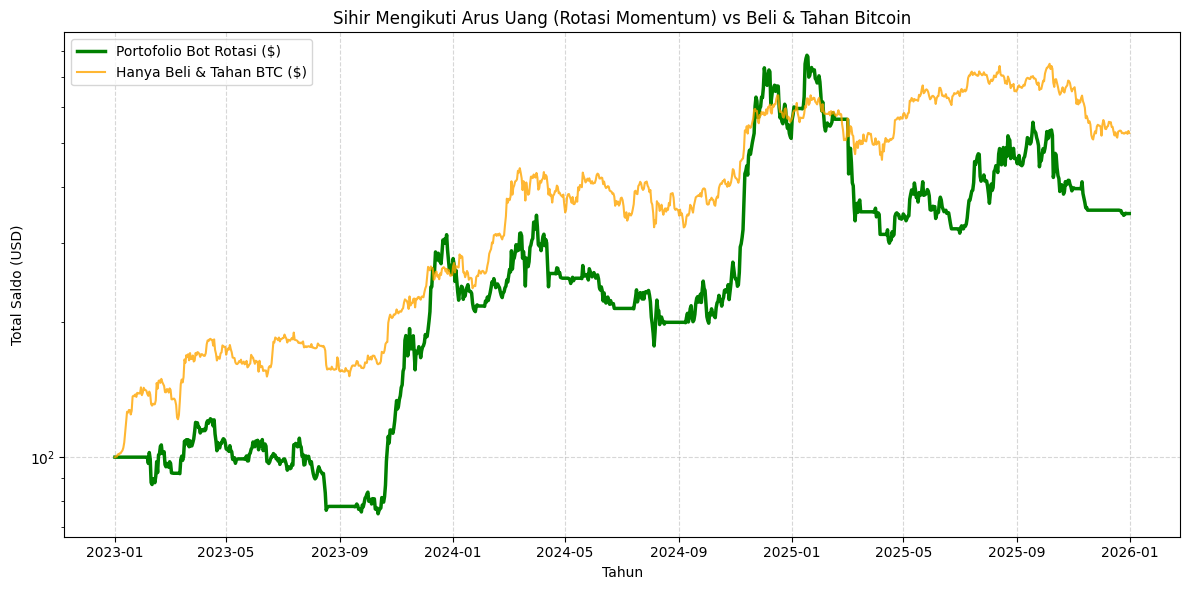

In [12]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. PARAMETER STRATEGI ROTASI
# ==========================================
# Daftar koin yang diawasi oleh Bot Scanner
tickers = ['BTC-USD', 'ETH-USD', 'SOL-USD', 'BNB-USD', 'XRP-USD', 
           'ADA-USD', 'AVAX-USD', 'LINK-USD', 'DOT-USD', 'DOGE-USD']

start_date = '2023-01-01'
end_date = '2026-01-01'

lookback_period = 30  # Bot mengukur momentum berdasarkan 30 hari ke belakang
rebalance_freq = 7    # Bot melakukan rotasi hanya setiap 7 hari sekali (Hemat Biaya!)
top_n = 2             # Bot mendiversifikasi modal ke 2 koin terbaik
trading_fee = 0.002   # Pajak transaksi bursa (0.2%)

# ==========================================
# 2. PENGAMBILAN & PERSIAPAN DATA
# ==========================================
print("1. Mendownload Data 10 Koin Raksasa (2023 - 2026)...")
df_close = yf.download(tickers, start=start_date, end=end_date)['Close']

# Bersihkan data jika ada koin yang datanya bolong di hari tertentu
df_close = df_close.ffill().dropna()

# Hitung return harian murni untuk semua koin
df_returns = df_close.pct_change().fillna(0)

# ==========================================
# 3. MESIN BACKTEST (PORTFOLIO ROTATION)
# ==========================================
print("2. Menjalankan Algoritma Rotasi Momentum...")

modal_awal = 100.0  # Kita mulai dengan $100
saldo_rotasi = modal_awal
saldo_btc = modal_awal  # Ini untuk perbandingan jika kita hanya HODL Bitcoin

histori_saldo_rotasi = []
histori_saldo_btc = []
koin_dipegang = []      # Daftar koin yang sedang dipegang minggu ini
total_transaksi = 0

# Looping mesin waktu dari hari ke hari
for i in range(len(df_close)):
    # 1. Update Nilai Portofolio Harian
    if i > 0:
        # A. Update portofolio pasif (Buy & Hold BTC)
        saldo_btc *= (1 + df_returns['BTC-USD'].iloc[i])
        
        # B. Update portofolio bot rotasi (Rata-rata return dari 2 koin yang dipegang)
        if len(koin_dipegang) > 0:
            return_hari_ini = df_returns[koin_dipegang].iloc[i].mean()
            saldo_rotasi *= (1 + return_hari_ini)
            
    # 2. Waktunya Penilaian (Setiap 7 Hari, setelah hari ke-30)
    if i >= lookback_period and i % rebalance_freq == 0:
        
        # Hitung kenaikan harga 30 hari terakhir untuk semua 10 koin
        harga_sekarang = df_close.iloc[i]
        harga_lalu = df_close.iloc[i - lookback_period]
        momentum = (harga_sekarang - harga_lalu) / harga_lalu
        
        # Urutkan dari yang naiknya paling brutal sampai yang paling hancur
        momentum_sorted = momentum.sort_values(ascending=False)
        
        # FITUR KEAMANAN UTAMA (Absolute Momentum)
        # Bot HANYA mau melirik koin yang pertumbuhannya positif (> 0)
        # Jika top koin saja minus, bot akan mengosongkan keranjang (pindah ke CASH/USDT)
        kandidat_koin = momentum_sorted[momentum_sorted > 0].head(top_n).index.tolist()
        
        # Cek apakah bot perlu melakukan jual/beli minggu ini
        # Jika koin minggu ini berbeda dengan koin minggu lalu, bot harus transaksi
        if set(kandidat_koin) != set(koin_dipegang):
            saldo_rotasi *= (1 - trading_fee) # Potong pajak bursa 0.2%
            total_transaksi += 1
            
        # Perbarui koin yang dipegang untuk minggu depan
        koin_dipegang = kandidat_koin
    
    # Catat buku kas harian
    histori_saldo_rotasi.append(saldo_rotasi)
    histori_saldo_btc.append(saldo_btc)

# Masukkan ke dalam tabel (DataFrame) agar mudah divisualisasi
df_hasil = pd.DataFrame(index=df_close.index)
df_hasil['Bot Rotasi'] = histori_saldo_rotasi
df_hasil['Hold BTC'] = histori_saldo_btc

# Hitung Maximum Drawdown (Penurunan Terburuk)
mdd_rotasi = ((df_hasil['Bot Rotasi'] - df_hasil['Bot Rotasi'].cummax()) / df_hasil['Bot Rotasi'].cummax() * 100).min()
mdd_btc = ((df_hasil['Hold BTC'] - df_hasil['Hold BTC'].cummax()) / df_hasil['Hold BTC'].cummax() * 100).min()

# ==========================================
# 4. LAPORAN & VISUALISASI
# ==========================================
roi_rotasi = ((saldo_rotasi - modal_awal) / modal_awal) * 100
roi_btc = ((saldo_btc - modal_awal) / modal_awal) * 100

print("\n" + "="*50)
print("🏆 HASIL PERTANDINGAN: BOT ROTASI vs HOLD BITCOIN")
print("="*50)
print(f"Modal Awal               : ${modal_awal:.2f}")
print(f"Saldo Akhir (Hold BTC)   : ${saldo_btc:.2f} (ROI: {roi_btc:.2f}%)")
print(f"Saldo Akhir (Bot Rotasi) : ${saldo_rotasi:.2f} (ROI: {roi_rotasi:.2f}%)")
print("-" * 50)
print(f"Max Drawdown (Hold BTC)  : {mdd_btc:.2f}% (Rasa sakit ditahan)")
print(f"Max Drawdown (Bot Rotasi): {mdd_rotasi:.2f}% (Rasa sakit bot)")
print(f"Total Eksekusi Transaksi : {total_transaksi} kali dalam 3 tahun")
print("="*50)

plt.figure(figsize=(12, 6))
plt.plot(df_hasil.index, df_hasil['Bot Rotasi'], color='green', linewidth=2.5, label='Portofolio Bot Rotasi ($)')
plt.plot(df_hasil.index, df_hasil['Hold BTC'], color='orange', linewidth=1.5, alpha=0.8, label='Hanya Beli & Tahan BTC ($)')

plt.title('Sihir Mengikuti Arus Uang (Rotasi Momentum) vs Beli & Tahan Bitcoin')
plt.xlabel('Tahun')
plt.ylabel('Total Saldo (USD)')
plt.yscale('log') # Menggunakan skala logaritmik agar pertumbuhan persentase terlihat jelas
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import ta # Library Technical Analysis (pip install ta)

# ==========================================
# KONFIGURASI GLOBAL
# ==========================================
UNIVERSE = ['BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'XRP-USD', 
            'ADA-USD', 'AVAX-USD', 'LINK-USD', 'DOT-USD', 'DOGE-USD']
MACRO_TIMEFRAME = '1d'
MICRO_TIMEFRAME = '1h'
MOMENTUM_LOOKBACK = 14 # Hari

# Parameter Asymmetric Bet (Target 3%, Batas Bawah -1%)
TARGET_PROFIT = 0.03
STOP_LOSS = 0.01
HORIZON_JAM = 24 # Waktu maksimal untuk mencapai target

# ==========================================
# FUNGSI HELPER (ANTI-BUG YFINANCE UPDATE)
# ==========================================
def fetch_crypto_data(ticker, period, interval):
    """
    Mengunduh data dan meratakan MultiIndex jika yfinance 
    menggunakan versi terbaru, agar tidak bentrok dengan library 'ta'.
    """
    df = yf.download(ticker, period=period, interval=interval, progress=False)
    
    # Jika kolom berbentuk MultiIndex (contoh: ('Close', 'BTC-USD')), buang level koinnya
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
        
    return df

# ==========================================
# LAYER 1: MACRO MOMENTUM ROTATION
# ==========================================
def layer1_get_top_coins(tickers, lookback=MOMENTUM_LOOKBACK):
    """
    Menghitung momentum 14-hari dan meranking koin.
    Hanya memilih 3 koin terbaik untuk di-trading-kan minggu ini.
    """
    print(f"🔄 [LAYER 1] Menjalankan pemindaian Momentum pada {len(tickers)} koin...")
    momentum_scores = {}
    
    for ticker in tickers:
        try:
            # Gunakan helper fetch_crypto_data
            df = fetch_crypto_data(ticker, period="1mo", interval="1d")
            if len(df) < lookback + 1:
                continue
                
            # Hitung Return sederhana selama 'lookback' hari
            current_close = df['Close'].iloc[-1].item()
            past_close = df['Close'].iloc[-(lookback+1)].item()
            
            momentum = (current_close - past_close) / past_close
            momentum_scores[ticker] = momentum
        except Exception as e:
            pass
            
    # Urutkan berdasarkan momentum tertinggi
    sorted_coins = sorted(momentum_scores.items(), key=lambda x: x[1], reverse=True)
    top_3 = [coin[0] for coin in sorted_coins[:3]]
    
    print(f"✅ [LAYER 1] 3 Koin Terpilih Minggu ini: {top_3}")
    return top_3

# ==========================================
# LAYER 2: ASYMMETRIC ML LABELING & TRAINING
# ==========================================
def create_asymmetric_labels(df, horizon, target_pct, sl_pct):
    """
    JANTUNG DARI STRATEGI INI. 
    Mencari tahu apakah dalam 'horizon' ke depan, harga menyentuh Target (+3%) 
    SEBELUM menyentuh Stop Loss (-1%).
    """
    labels = np.zeros(len(df))
    
    # Konversi ke array numpy untuk kecepatan komputasi
    highs = df['High'].values
    lows = df['Low'].values
    closes = df['Close'].values
    
    for i in range(len(df) - horizon):
        current_close = closes[i]
        target_price = current_close * (1 + target_pct)
        sl_price = current_close * (1 - sl_pct)
        
        hit_target = False
        
        # Look ahead dalam window horizon
        for j in range(1, horizon + 1):
            future_high = highs[i + j]
            future_low = lows[i + j]
            
            # Jika menyentuh Stop Loss duluan, gagal (0)
            if future_low <= sl_price:
                break
                
            # Jika menyentuh Target tanpa kena SL, berhasil (1)
            if future_high >= target_price:
                hit_target = True
                break
                
        if hit_target:
            labels[i] = 1
            
    return labels

def feature_engineering(df):
    """Menambahkan indikator teknikal sebagai 'mata' bagi AI."""
    df = df.copy()
    # Volatilitas
    df['ATR'] = ta.volatility.average_true_range(df['High'], df['Low'], df['Close'], window=14)
    # Momentum
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)
    # Tren
    df['MACD'] = ta.trend.macd_diff(df['Close'])
    # Volume Anomaly
    df['Vol_SMA'] = df['Volume'].rolling(24).mean()
    df['Vol_Ratio'] = df['Volume'] / df['Vol_SMA']
    
    return df.dropna()

def train_micro_model(ticker):
    """Mengambil data 1H, membuat label, melatih Random Forest."""
    print(f"🧠 [LAYER 2] Melatih AI untuk {ticker}...")
    
    # 1. Gunakan helper fetch_crypto_data
    df = fetch_crypto_data(ticker, period="1y", interval="1h")
    
    # 2. Tambahkan Fitur (X)
    df = feature_engineering(df)
    
    # 3. Tambahkan Label Asimetris (y)
    df['Target'] = create_asymmetric_labels(df, HORIZON_JAM, TARGET_PROFIT, STOP_LOSS)
    
    # Hapus data terakhir yang belum punya masa depan (horizon)
    df = df.iloc[:-HORIZON_JAM] 
    
    # 4. Siapkan X dan y
    features = ['ATR', 'RSI', 'MACD', 'Vol_Ratio']
    X = df[features]
    y = df['Target']
    
    # 5. Train-Test Split (Berurutan waktu, jangan di-shuffle!)
    split = int(len(df) * 0.8)
    X_train, X_test = X.iloc[:split], X.iloc[split:]
    y_train, y_test = y.iloc[:split], y.iloc[split:]
    
    # 6. Latih Model (Fokus pada menghindari False Positive)
    model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
    model.fit(X_train, y_train)
    
    print(f"✅ [LAYER 2] Model siap. Distribusi Label Train: {sum(y_train)} Win / {len(y_train)} Total")
    return model, features

# ==========================================
# LAYER 3: LIVE EXECUTION ENGINE (SIMULATION)
# ==========================================
def live_trading_bot():
    print("🚀 MEMULAI SISTEM AUTO-TRADING HYBRID...\n" + "="*40)
    
    # LANGKAH 1: Filter Makro (Dilakukan setiap minggu)
    top_3_coins = layer1_get_top_coins(UNIVERSE)
    
    models = {}
    
    # LANGKAH 2: Latih/Load Model khusus untuk 3 koin tersebut
    for coin in top_3_coins:
        model, feature_cols = train_micro_model(coin)
        models[coin] = {'model': model, 'features': feature_cols}
        
    print("\n" + "="*40)
    print("⏳ [LAYER 3] Menunggu Sinyal Eksekusi (Simulasi Data Terakhir)...")
    
    # LANGKAH 3: Looping Pengecekan Real-time (Sistem 1-Jam)
    for coin in top_3_coins:
        # Gunakan helper fetch_crypto_data
        df_live = fetch_crypto_data(coin, period="5d", interval="1h")
        df_live = feature_engineering(df_live)
        
        # Ambil baris data paling ujung (paling baru)
        latest_data = df_live.iloc[-1:]
        X_live = latest_data[models[coin]['features']]
        
        # Minta AI memprediksi PROBABILITAS
        ai_model = models[coin]['model']
        prob_naik = ai_model.predict_proba(X_live)[0][1] # Ambil probabilitas kelas '1'
        
        print(f"📊 {coin} -> Probabilitas Asymmetric Tembus (+3% sblm -1%): {prob_naik:.1%}")
        
        # LOGIKA EKSEKUSI BOT
        if prob_naik >= 0.80: # Threshold sangat ketat
            print(f"   🟢 [BUY SIGNAL] Tarik Pelatuk di {coin}! AI sangat yakin.")
            print(f"   ⚙️ Set limit order Beli. Pasang TP +{TARGET_PROFIT*100}% dan SL -{STOP_LOSS*100}%")
        else:
            print(f"   🔴 [PASS] Probabilitas di bawah 80%. Bot diam untuk hemat fee.")

# Eksekusi Skrip
if __name__ == "__main__":
    live_trading_bot()

🚀 MEMULAI SISTEM AUTO-TRADING HYBRID...
🔄 [LAYER 1] Menjalankan pemindaian Momentum pada 10 koin...
✅ [LAYER 1] 3 Koin Terpilih Minggu ini: ['ETH-USD', 'BTC-USD', 'AVAX-USD']
🧠 [LAYER 2] Melatih AI untuk ETH-USD...
✅ [LAYER 2] Model siap. Distribusi Label Train: 1530.0 Win / 6928 Total
🧠 [LAYER 2] Melatih AI untuk BTC-USD...
✅ [LAYER 2] Model siap. Distribusi Label Train: 615.0 Win / 6923 Total
🧠 [LAYER 2] Melatih AI untuk AVAX-USD...
✅ [LAYER 2] Model siap. Distribusi Label Train: 1707.0 Win / 6908 Total

⏳ [LAYER 3] Menunggu Sinyal Eksekusi (Simulasi Data Terakhir)...
📊 ETH-USD -> Probabilitas Asymmetric Tembus (+3% sblm -1%): 59.6%
   🔴 [PASS] Probabilitas di bawah 80%. Bot diam untuk hemat fee.
📊 BTC-USD -> Probabilitas Asymmetric Tembus (+3% sblm -1%): 46.0%
   🔴 [PASS] Probabilitas di bawah 80%. Bot diam untuk hemat fee.
📊 AVAX-USD -> Probabilitas Asymmetric Tembus (+3% sblm -1%): 47.5%
   🔴 [PASS] Probabilitas di bawah 80%. Bot diam untuk hemat fee.


In [16]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
import ta
import itertools
import warnings
warnings.filterwarnings('ignore') # Menyembunyikan warning pandas agar terminal bersih

# ==========================================
# KONFIGURASI GLOBAL
# ==========================================
TARGET_COIN = 'ETH-USD' # Kita gunakan ETH untuk optimasi agar cepat
DATA_PERIOD = '2y'      # Tarik data 2 tahun ke belakang
DATA_INTERVAL = '1h'
HORIZON_JAM = 24
TRADING_FEE = 0.002     # Asumsi fee 0.2% per transaksi (Taker fee)

# Parameter yang akan diuji oleh OPTIMIZER (Grid Search)
GRID_TP = [0.02, 0.03, 0.04]       # Target Profit: 2%, 3%, 4%
GRID_SL = [0.01, 0.015, 0.02]      # Stop Loss: 1%, 1.5%, 2%
GRID_THRESH = [0.65, 0.70, 0.75]   # Minimal keyakinan AI: 65%, 70%, 75%

# ==========================================
# 1. DATA PIPELINE
# ==========================================
def fetch_crypto_data(ticker, period, interval):
    print(f"📥 Mengunduh data historis {ticker}...")
    df = yf.download(ticker, period=period, interval=interval, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
    return df

def feature_engineering(df):
    df = df.copy()
    df['ATR'] = ta.volatility.average_true_range(df['High'], df['Low'], df['Close'], window=14)
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)
    df['MACD'] = ta.trend.macd_diff(df['Close'])
    df['Vol_SMA'] = df['Volume'].rolling(24).mean()
    df['Vol_Ratio'] = df['Volume'] / df['Vol_SMA']
    return df.dropna()

def create_asymmetric_labels(df, horizon, target_pct, sl_pct):
    labels = np.zeros(len(df))
    highs, lows, closes = df['High'].values, df['Low'].values, df['Close'].values
    
    for i in range(len(df) - horizon):
        target_price = closes[i] * (1 + target_pct)
        sl_price = closes[i] * (1 - sl_pct)
        
        hit_target = False
        for j in range(1, horizon + 1):
            if lows[i + j] <= sl_price:
                break # Kena SL duluan
            if highs[i + j] >= target_price:
                hit_target = True
                break # Kena TP!
                
        if hit_target:
            labels[i] = 1
    return labels

# ==========================================
# 2. VECTORIZED BACKTESTER ENGINE
# ==========================================
def run_backtest(y_true, y_prob, threshold, tp, sl, fee):
    """
    Simulasi super cepat. 
    Jika probabilitas > threshold, bot beli.
    Jika y_true == 1 (Berhasil), untung = TP - (2*fee)
    Jika y_true == 0 (Gagal), rugi = -SL - (2*fee)
    """
    signals = (y_prob >= threshold).astype(int)
    
    # Hitung Return per transaksi
    # 2*fee karena bayar fee saat beli dan saat jual
    win_return = tp - (2 * fee)
    loss_return = -sl - (2 * fee)
    
    # Asumsikan jika trade diambil (signal=1): 
    # Jika label asli 1, maka win. Jika 0, maka loss.
    trade_returns = np.where(signals == 1, 
                             np.where(y_true == 1, win_return, loss_return), 
                             0) # Jika signal 0, return 0 (diam)
    
    # Hindari compounding error (hanya ambil trade berurutan jika tidak overlap)
    # Untuk penyederhanaan vectorized, kita asumsikan bisa paralel trade.
    
    total_trades = np.sum(signals)
    winning_trades = np.sum((signals == 1) & (y_true == 1))
    
    win_rate = (winning_trades / total_trades) * 100 if total_trades > 0 else 0
    
    # Kurva Ekuitas (Mulai dari 100%)
    cumulative_returns = np.cumsum(trade_returns)
    equity_curve = 1 + cumulative_returns
    
    # Hitung Maximum Drawdown (MDD)
    running_max = np.maximum.accumulate(equity_curve)
    drawdowns = (equity_curve / running_max) - 1
    max_drawdown = np.min(drawdowns) * 100
    
    total_roi = cumulative_returns[-1] * 100 if len(cumulative_returns) > 0 else 0
    
    return {
        'Total Trades': total_trades,
        'Win Rate (%)': win_rate,
        'ROI (%)': total_roi,
        'Max Drawdown (%)': max_drawdown
    }

# ==========================================
# 3. AUTO-OPTIMIZER (GRID SEARCH)
# ==========================================
def optimize_strategy(df):
    print("\n" + "="*50)
    print("⚙️ MEMULAI OPTIMASI OTOMATIS (TRAINING & BACKTESTING)")
    print("="*50)
    
    best_roi = -999
    best_params = {}
    best_stats = {}
    
    features = ['ATR', 'RSI', 'MACD', 'Vol_Ratio']
    
    # 1. Split Data (80% Train, 20% Out-of-Sample Test)
    # OOS Test digunakan agar Backtest mensimulasikan masa depan yang belum pernah dilihat AI
    split_idx = int(len(df) * 0.8)
    df_train = df.iloc[:split_idx].copy()
    df_test = df.iloc[split_idx:].copy()
    
    X_train_base = df_train[features]
    X_test_base = df_test[features]
    
    # Generate semua kombinasi (TP, SL, Threshold)
    combinations = list(itertools.product(GRID_TP, GRID_SL, GRID_THRESH))
    print(f"🔍 Menguji {len(combinations)} kombinasi strategi...")
    
    for idx, (tp, sl, thresh) in enumerate(combinations):
        # Buat label dinamis berdasarkan TP dan SL saat ini
        y_train = create_asymmetric_labels(df_train, HORIZON_JAM, tp, sl)
        y_test = create_asymmetric_labels(df_test, HORIZON_JAM, tp, sl)
        
        # Skip jika rasio label terlalu ekstrem (misal tidak pernah hit TP)
        if sum(y_train) < 50:
            continue
            
        # Latih AI
        model = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42, class_weight='balanced')
        model.fit(X_train_base, y_train)
        
        # Prediksi probabilitas di Out-of-Sample Test
        y_prob = model.predict_proba(X_test_base)[:, 1]
        
        # Jalankan Backtester
        stats = run_backtest(y_test, y_prob, thresh, tp, sl, TRADING_FEE)
        
        # Log Progress per 10 kombinasi
        if (idx + 1) % 10 == 0:
            print(f"   ⏳ Selesai {idx+1}/{len(combinations)} kombinasi...")
            
        # Simpan jika ini ROI terbaik DAN trading lebih dari 10 kali
        if stats['ROI (%)'] > best_roi and stats['Total Trades'] >= 10:
            best_roi = stats['ROI (%)']
            best_params = {'TP': tp, 'SL': sl, 'Threshold': thresh}
            best_stats = stats

    print("\n🏆 OPTIMASI SELESAI! BERIKUT PARAMETER TERBAIK:")
    print(f"   🎯 Target Profit (TP) : {best_params['TP']*100:.1f}%")
    print(f"   🛡️ Stop Loss (SL)   : {best_params['SL']*100:.1f}%")
    print(f"   🧠 Min Prob AI (Thr): {best_params['Threshold']*100:.1f}%")
    
    print("\n📊 HASIL BACKTEST (OUT-OF-SAMPLE - DATA BELUM PERNAH DILIHAT AI):")
    print(f"   Total Transaksi : {best_stats['Total Trades']} kali")
    print(f"   Win Rate        : {best_stats['Win Rate (%)']:.2f}%")
    print(f"   Total Net ROI   : {best_stats['ROI (%)']:.2f}% (Setelah Potong Fee)")
    print(f"   Max Drawdown    : {best_stats['Max Drawdown (%)']:.2f}%")
    
    return best_params

# Eksekusi Utama
if __name__ == "__main__":
    # 1. Siapkan Data Obyek Studi
    raw_data = fetch_crypto_data(TARGET_COIN, DATA_PERIOD, DATA_INTERVAL)
    clean_data = feature_engineering(raw_data)
    
    # 2. Jalankan Mesin Optimizer & Backtester
    optimize_strategy(clean_data)

📥 Mengunduh data historis ETH-USD...

⚙️ MEMULAI OPTIMASI OTOMATIS (TRAINING & BACKTESTING)
🔍 Menguji 27 kombinasi strategi...
   ⏳ Selesai 10/27 kombinasi...
   ⏳ Selesai 20/27 kombinasi...

🏆 OPTIMASI SELESAI! BERIKUT PARAMETER TERBAIK:
   🎯 Target Profit (TP) : 3.0%
   🛡️ Stop Loss (SL)   : 2.0%
   🧠 Min Prob AI (Thr): 65.0%

📊 HASIL BACKTEST (OUT-OF-SAMPLE - DATA BELUM PERNAH DILIHAT AI):
   Total Transaksi : 14 kali
   Win Rate        : 42.86%
   Total Net ROI   : -3.60% (Setelah Potong Fee)
   Max Drawdown    : -19.20%


In [17]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
import ta
import itertools
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# KONFIGURASI GLOBAL (UPDATED FEE)
# ==========================================
TARGET_COIN = 'ETH-USD'
DATA_PERIOD = '2y'
DATA_INTERVAL = '1h'
HORIZON_JAM = 24
TRADING_FEE = 0.003     # <--- Diubah menjadi 0.3% (Konservatif)

# Parameter Optimasi
GRID_TP = [0.03, 0.04, 0.05]       # Target ditingkatkan karena fee naik
GRID_SL = [0.015, 0.02, 0.025]
GRID_THRESH = [0.70, 0.75, 0.80]   # Threshold diperketat

def fetch_crypto_data(ticker, period, interval):
    print(f"📥 Mengunduh data historis {ticker}...")
    df = yf.download(ticker, period=period, interval=interval, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
    return df

# ==========================================
# 2. MEMPERCERDAS AI (FEATURE ENGINEERING)
# ==========================================
def feature_engineering(df):
    df = df.copy()
    
    # Indikator Dasar
    df['ATR'] = ta.volatility.average_true_range(df['High'], df['Low'], df['Close'], window=14)
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)
    
    # --- FITUR CERDAS BARU ---
    
    # A. Trend Context (EMA 200 sebagai Filter Tren Makro)
    df['EMA_200'] = df['Close'].ewm(span=200).mean()
    df['Above_Trend'] = (df['Close'] > df['EMA_200']).astype(int)
    
    # B. Volatility Regime (Z-Score ATR)
    # Mendeteksi apakah volatilitas sedang aneh/tinggi dibanding rata-rata
    df['ATR_Mean'] = df['ATR'].rolling(50).mean()
    df['ATR_Std'] = df['ATR'].rolling(50).std()
    df['Vol_Regime'] = (df['ATR'] - df['ATR_Mean']) / df['ATR_Std']
    
    # C. Price Distance (Mendeteksi jenuh beli/jual secara relatif)
    df['EMA_50'] = df['Close'].ewm(span=50).mean()
    df['Dist_EMA_50'] = (df['Close'] - df['EMA_50']) / df['EMA_50']
    
    # D. Volume Momentum
    df['Vol_Ratio'] = df['Volume'] / df['Volume'].rolling(24).mean()
    
    return df.dropna()

def create_asymmetric_labels(df, horizon, target_pct, sl_pct):
    labels = np.zeros(len(df))
    highs, lows, closes = df['High'].values, df['Low'].values, df['Close'].values
    for i in range(len(df) - horizon):
        target_price = closes[i] * (1 + target_pct)
        sl_price = closes[i] * (1 - sl_pct)
        hit_target = False
        for j in range(1, horizon + 1):
            if lows[i + j] <= sl_price: break
            if highs[i + j] >= target_price:
                hit_target = True
                break
        if hit_target: labels[i] = 1
    return labels

def run_backtest(y_true, y_prob, threshold, tp, sl, fee):
    signals = (y_prob >= threshold).astype(int)
    win_return = tp - (2 * fee)
    loss_return = -sl - (2 * fee)
    trade_returns = np.where(signals == 1, np.where(y_true == 1, win_return, loss_return), 0)
    
    total_trades = np.sum(signals)
    winning_trades = np.sum((signals == 1) & (y_true == 1))
    win_rate = (winning_trades / total_trades) * 100 if total_trades > 0 else 0
    cumulative_returns = np.cumsum(trade_returns)
    total_roi = cumulative_returns[-1] * 100 if len(cumulative_returns) > 0 else 0
    
    # Drawdown calculation
    equity_curve = 1 + cumulative_returns
    max_drawdown = (np.min(equity_curve / np.maximum.accumulate(equity_curve)) - 1) * 100
    
    return {'Total Trades': total_trades, 'Win Rate (%)': win_rate, 'ROI (%)': total_roi, 'Max Drawdown (%)': max_drawdown}

def optimize_strategy(df):
    print("\n" + "="*50)
    print("⚙️ OPTIMASI DENGAN FITUR AI CERDAS & FEE 0.3%")
    print("="*50)
    
    best_roi, best_params, best_stats = -999, {}, {}
    features = ['ATR', 'RSI', 'Above_Trend', 'Vol_Regime', 'Dist_EMA_50', 'Vol_Ratio']
    
    split_idx = int(len(df) * 0.8)
    df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]
    X_train, X_test = df_train[features], df_test[features]
    
    combinations = list(itertools.product(GRID_TP, GRID_SL, GRID_THRESH))
    
    for tp, sl, thresh in combinations:
        y_train = create_asymmetric_labels(df_train, HORIZON_JAM, tp, sl)
        y_test = create_asymmetric_labels(df_test, HORIZON_JAM, tp, sl)
        
        if sum(y_train) < 30: continue
            
        model = RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42, class_weight='balanced')
        model.fit(X_train, y_train)
        y_prob = model.predict_proba(X_test)[:, 1]
        
        stats = run_backtest(y_test, y_prob, thresh, tp, sl, TRADING_FEE)
        
        if stats['ROI (%)'] > best_roi and stats['Total Trades'] >= 5:
            best_roi, best_params, best_stats = stats['ROI (%)'], {'TP': tp, 'SL': sl, 'Threshold': thresh}, stats

    print(f"\n🏆 PARAMETER EMAS: TP={best_params['TP']*100}%, SL={best_params['SL']*100}%, Prob={best_params['Threshold']*100}%")
    print(f"📊 HASIL OOS: ROI={best_stats['ROI (%)']:.2f}%, WinRate={best_stats['Win Rate (%)']:.2f}%, Trades={best_stats['Total Trades']}")

if __name__ == "__main__":
    raw_data = fetch_crypto_data(TARGET_COIN, DATA_PERIOD, DATA_INTERVAL)
    clean_data = feature_engineering(raw_data)
    optimize_strategy(clean_data)

📥 Mengunduh data historis ETH-USD...

⚙️ OPTIMASI DENGAN FITUR AI CERDAS & FEE 0.3%

🏆 PARAMETER EMAS: TP=3.0%, SL=2.0%, Prob=70.0%
📊 HASIL OOS: ROI=14.20%, WinRate=87.50%, Trades=8


In [18]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
import ta
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. KONFIGURASI GLOBAL & PARAMETER EMAS
# ==========================================
TARGET_COIN = 'ETH-USD'
DATA_PERIOD = '2y'
DATA_INTERVAL = '1h'

# Parameter Pemenang dari Optimasi Sebelumnya
TP = 0.03          # Target Profit 3%
SL = 0.02          # Stop Loss 2%
THRESH = 0.70      # Min Probabilitas AI 70%
TRADING_FEE = 0.003 # Taker Fee 0.3%
HORIZON_JAM = 24

# Konfigurasi Walk-Forward (WFO)
# Menggunakan data 1H: 30 hari = 720 baris
TRAIN_WINDOW_DAYS = 180  # AI selalu belajar dari 6 bulan terakhir
TEST_WINDOW_DAYS = 60    # AI diuji di 2 bulan ke depan (Out-of-Sample)

# ==========================================
# 2. DATA PIPELINE & FEATURE ENGINEERING
# ==========================================
def fetch_crypto_data(ticker, period, interval):
    print(f"📥 Mengunduh data historis {ticker}...")
    df = yf.download(ticker, period=period, interval=interval, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
    return df

def feature_engineering(df):
    df = df.copy()
    # Indikator Dasar
    df['ATR'] = ta.volatility.average_true_range(df['High'], df['Low'], df['Close'], window=14)
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)
    
    # Fitur Cerdas (Trend, Volatility, Price Distance, Volume)
    df['EMA_200'] = df['Close'].ewm(span=200).mean()
    df['Above_Trend'] = (df['Close'] > df['EMA_200']).astype(int)
    
    df['ATR_Mean'] = df['ATR'].rolling(50).mean()
    df['ATR_Std'] = df['ATR'].rolling(50).std()
    df['Vol_Regime'] = (df['ATR'] - df['ATR_Mean']) / df['ATR_Std']
    
    df['EMA_50'] = df['Close'].ewm(span=50).mean()
    df['Dist_EMA_50'] = (df['Close'] - df['EMA_50']) / df['EMA_50']
    
    df['Vol_Ratio'] = df['Volume'] / df['Volume'].rolling(24).mean()
    
    return df.dropna()

def create_asymmetric_labels(df, horizon, target_pct, sl_pct):
    labels = np.zeros(len(df))
    highs, lows, closes = df['High'].values, df['Low'].values, df['Close'].values
    for i in range(len(df) - horizon):
        target_price = closes[i] * (1 + target_pct)
        sl_price = closes[i] * (1 - sl_pct)
        hit_target = False
        for j in range(1, horizon + 1):
            if lows[i + j] <= sl_price: break
            if highs[i + j] >= target_price:
                hit_target = True
                break
        if hit_target: labels[i] = 1
    return labels

# ==========================================
# 3. MESIN WALK-FORWARD VALIDATION
# ==========================================
def run_wfo_backtest(df):
    print("\n" + "="*60)
    print("🛡️ MEMULAI UJI KETAHANAN BAJA (WALK-FORWARD VALIDATION)")
    print("="*60)
    
    features = ['ATR', 'RSI', 'Above_Trend', 'Vol_Regime', 'Dist_EMA_50', 'Vol_Ratio']
    
    # Tambahkan Label ke seluruh dataset
    df['Target'] = create_asymmetric_labels(df, HORIZON_JAM, TP, SL)
    df = df.dropna()
    
    # Konversi hari ke baris (asumsi 1 hari = 24 baris data 1H)
    train_size = TRAIN_WINDOW_DAYS * 24
    test_size = TEST_WINDOW_DAYS * 24
    
    total_rows = len(df)
    
    if total_rows < (train_size + test_size):
        print("❌ Data terlalu sedikit untuk Walk-Forward. Tarik periode yang lebih lama.")
        return
        
    fold = 1
    total_oos_trades = 0
    total_oos_wins = 0
    all_oos_returns = []
    
    # Looping melintasi waktu (Maju sebesar test_size setiap iterasi)
    for start_idx in range(0, total_rows - train_size - test_size + 1, test_size):
        train_end = start_idx + train_size
        test_end = train_end + test_size
        
        df_train = df.iloc[start_idx:train_end]
        df_test = df.iloc[train_end:test_end]
        
        date_train_start = df_train.index[0].strftime('%Y-%m-%d')
        date_test_start = df_test.index[0].strftime('%Y-%m-%d')
        date_test_end = df_test.index[-1].strftime('%Y-%m-%d')
        
        # Pisahkan Fitur dan Label
        X_train, y_train = df_train[features], df_train['Target']
        X_test, y_test = df_test[features], df_test['Target']
        
        # Validasi: Pastikan ada cukup kejadian positif di data latih agar AI bisa belajar
        if sum(y_train) < 20:
            print(f"⏩ Fold {fold} dilewati (Terlalu sedikit volatilitas di periode latih)")
            continue
            
        # Latih AI (Model beradaptasi dengan kondisi 6 bulan terakhir)
        model = RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42, class_weight='balanced')
        model.fit(X_train, y_train)
        
        # Uji di masa depan yang tidak diketahui (2 bulan ke depan)
        y_prob = model.predict_proba(X_test)[:, 1]
        
        # Eksekusi Sinyal OOS
        signals = (y_prob >= THRESH).astype(int)
        
        # Kalkulasi Return Per Fold
        win_return = TP - (2 * TRADING_FEE)
        loss_return = -SL - (2 * TRADING_FEE)
        
        trade_returns = np.where(signals == 1, 
                                 np.where(y_test == 1, win_return, loss_return), 
                                 0)
        
        trades_taken = np.sum(signals)
        wins = np.sum((signals == 1) & (y_test == 1))
        roi_fold = np.sum(trade_returns) * 100
        
        # Simpan akumulasi
        total_oos_trades += trades_taken
        total_oos_wins += wins
        all_oos_returns.extend(trade_returns[signals == 1])
        
        # Print Log per Gerbong Waktu
        win_rate_str = f"{(wins/trades_taken)*100:.1f}%" if trades_taken > 0 else "0.0%"
        print(f"📊 Fold {fold} | Uji: {date_test_start} sd {date_test_end}")
        print(f"   Trades: {trades_taken} | Win Rate: {win_rate_str} | Net ROI: {roi_fold:+.2f}%")
        
        fold += 1

    # ==========================================
    # KALKULASI FINAL AGREGAT SELURUH FOLD
    # ==========================================
    print("\n" + "="*60)
    print("🏆 KESIMPULAN AKHIR WALK-FORWARD (TOTAL OUT-OF-SAMPLE)")
    print("="*60)
    
    if total_oos_trades > 0:
        final_win_rate = (total_oos_wins / total_oos_trades) * 100
        final_roi = np.sum(all_oos_returns) * 100
        
        # Hitung Drawdown dari array return
        cumulative = np.cumsum(all_oos_returns)
        equity = 1 + cumulative
        running_max = np.maximum.accumulate(equity)
        drawdowns = (equity / running_max) - 1
        mdd = np.min(drawdowns) * 100 if len(drawdowns) > 0 else 0
        
        print(f"   🔥 Total Eksekusi Live (Simulasi) : {total_oos_trades} Trades")
        print(f"   🎯 Akurasi (Win Rate) Agregat    : {final_win_rate:.2f}%")
        print(f"   💰 Total Net Profit Bersih       : {final_roi:+.2f}%")
        print(f"   📉 Maximum Drawdown Agregat      : {mdd:.2f}%")
        
        if final_roi > 0:
            print("\n✅ KESIMPULAN: STRATEGI ROBUST. Lolos Uji Baja melintasi berbagai rezim pasar.")
        else:
            print("\n❌ KESIMPULAN: STRATEGI OVERFIT. Gagal bertahan di beberapa rezim pasar tertentu.")
    else:
        print("Bot tidak menemukan satu pun sinyal yang layak dieksekusi selama periode pengujian.")

# Eksekusi Skrip
if __name__ == "__main__":
    raw_data = fetch_crypto_data(TARGET_COIN, DATA_PERIOD, DATA_INTERVAL)
    clean_data = feature_engineering(raw_data)
    run_wfo_backtest(clean_data)

📥 Mengunduh data historis ETH-USD...

🛡️ MEMULAI UJI KETAHANAN BAJA (WALK-FORWARD VALIDATION)
📊 Fold 1 | Uji: 2024-10-14 sd 2024-12-14
   Trades: 44 | Win Rate: 56.8% | Net ROI: +10.60%
📊 Fold 2 | Uji: 2024-12-14 sd 2025-02-12
   Trades: 134 | Win Rate: 29.9% | Net ROI: -148.40%
📊 Fold 3 | Uji: 2025-02-13 sd 2025-04-13
   Trades: 16 | Win Rate: 31.2% | Net ROI: -16.60%
📊 Fold 4 | Uji: 2025-04-14 sd 2025-06-12
   Trades: 14 | Win Rate: 0.0% | Net ROI: -36.40%
📊 Fold 5 | Uji: 2025-06-13 sd 2025-08-11
   Trades: 2 | Win Rate: 50.0% | Net ROI: -0.20%
📊 Fold 6 | Uji: 2025-08-12 sd 2025-10-11
   Trades: 3 | Win Rate: 0.0% | Net ROI: -7.80%
📊 Fold 7 | Uji: 2025-10-11 sd 2025-12-11
   Trades: 9 | Win Rate: 44.4% | Net ROI: -3.40%
📊 Fold 8 | Uji: 2025-12-11 sd 2026-02-09
   Trades: 39 | Win Rate: 48.7% | Net ROI: -6.40%
📊 Fold 9 | Uji: 2026-02-09 sd 2026-04-10
   Trades: 0 | Win Rate: 0.0% | Net ROI: +0.00%

🏆 KESIMPULAN AKHIR WALK-FORWARD (TOTAL OUT-OF-SAMPLE)
   🔥 Total Eksekusi Live (Simulas

In [22]:
import pandas as pd
import numpy as np
import yfinance as yf
from sklearn.ensemble import RandomForestClassifier
import ta
import itertools
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. KONFIGURASI GLOBAL 4H
# ==========================================
TARGET_COIN = 'ETH-USD'
DATA_PERIOD = '2y'
DATA_INTERVAL = '4h' 
TRADING_FEE = 0.003  
HORIZON_LILIN = 12   

# --- PERUBAHAN KRUSIAL DI SINI ---
GRID_TP = [0.04, 0.05, 0.06]       
GRID_SL = [0.02, 0.03, 0.04]       
# Threshold diturunkan ke level probabilitas RF yang realistis
GRID_THRESH = [0.53, 0.55, 0.60]   

def fetch_crypto_data(ticker, period, interval):
    print(f"📥 Mengunduh data historis {ticker} ({interval})...")
    df = yf.download(ticker, period=period, interval=interval, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
    return df

# ==========================================
# 2. FEATURE ENGINEERING (OPTIMIZED FOR 4H)
# ==========================================
def feature_engineering(df):
    df = df.copy()
    df['RSI'] = ta.momentum.rsi(df['Close'], window=14)
    df['EMA_200'] = df['Close'].ewm(span=200).mean()
    df['Above_Trend'] = (df['Close'] > df['EMA_200']).astype(int)
    
    bb = ta.volatility.BollingerBands(df['Close'], window=20, window_dev=2)
    df['BB_Width'] = bb.bollinger_wband()
    df['ATR_Ratio'] = ta.volatility.average_true_range(df['High'], df['Low'], df['Close'], window=14) / df['Close']
    df['Vol_Z'] = (df['Volume'] - df['Volume'].rolling(24).mean()) / df['Volume'].rolling(24).std()
    
    return df.dropna()

def create_labels(df, horizon, tp_pct, sl_pct):
    labels = np.zeros(len(df))
    highs, lows, closes = df['High'].values, df['Low'].values, df['Close'].values
    for i in range(len(df) - horizon):
        t_price, s_price = closes[i]*(1+tp_pct), closes[i]*(1-sl_pct)
        for j in range(1, horizon + 1):
            if lows[i+j] <= s_price: break 
            if highs[i+j] >= t_price:
                labels[i] = 1 
                break
    return labels

# ==========================================
# 3. AUTO-OPTIMIZER & BACKTESTER
# ==========================================
def run_optimized_backtest(df):
    print("\n" + "="*50)
    print("⚙️ MENJALANKAN AUTO-OPTIMIZATION (TIMEFRAME 4H)")
    print("="*50)
    
    features = ['RSI', 'Above_Trend', 'BB_Width', 'ATR_Ratio', 'Vol_Z']
    split_idx = int(len(df) * 0.7)
    df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]
    
    best_roi, best_params = -999, {}
    combinations = list(itertools.product(GRID_TP, GRID_SL, GRID_THRESH))
    
    for tp, sl, thresh in combinations:
        y_train = create_labels(df_train, HORIZON_LILIN, tp, sl)
        if sum(y_train) < 15: continue
            
        model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
        model.fit(df_train[features], y_train)
        y_prob = model.predict_proba(df_test[features])[:, 1]
        
        signals = (y_prob >= thresh).astype(int)
        y_test_real = create_labels(df_test, HORIZON_LILIN, tp, sl)
        
        win_ret, loss_ret = tp - (2*TRADING_FEE), -sl - (2*TRADING_FEE)
        rets = np.where(signals == 1, np.where(y_test_real == 1, win_ret, loss_ret), 0)
        roi = np.sum(rets) * 100
        
        # Syarat: Harus ada minimal 5 trade agar statistik valid
        if roi > best_roi and np.sum(signals) >= 5:
            best_roi, best_params = roi, {'TP': tp, 'SL': sl, 'Threshold': thresh, 'Model': model}

    print("\n🏆 PARAMETER TERBAIK DITEMUKAN:")
    
    # --- SAFETY CATCH (Mencegah Crash) ---
    if not best_params:
        print("   ❌ AI terlalu takut untuk mengeksekusi perdagangan (Total Trade < 5).")
        print("   💡 Penjelasan: Bahkan dengan threshold yang diturunkan, pasar OOS (Out-of-Sample)")
        print("      tidak memberikan pola yang AI yakini. Ini mencegah Anda dari kerugian!")
        return

    print(f"   Target Profit: {best_params['TP']*100}% | SL: {best_params['SL']*100}% | Thr: {best_params['Threshold']*100}%")
    
    # --- EVALUASI FINAL PADA DATA TEST ---
    model = best_params['Model']
    y_final_prob = model.predict_proba(df_test[features])[:, 1]
    final_signals = (y_final_prob >= best_params['Threshold']).astype(int)
    y_final_real = create_labels(df_test, HORIZON_LILIN, best_params['TP'], best_params['SL'])
    
    final_win_ret = best_params['TP'] - (2*TRADING_FEE)
    final_loss_ret = -best_params['SL'] - (2*TRADING_FEE)
    final_rets = np.where(final_signals == 1, np.where(y_final_real == 1, final_win_ret, final_loss_ret), 0)
    
    total_trades = np.sum(final_signals)
    win_rate = (np.sum((final_signals == 1) & (y_final_real == 1)) / total_trades) * 100 if total_trades > 0 else 0
    
    print("\n📊 HASIL BACKTEST DATA TEST (OUT-OF-SAMPLE):")
    print(f"   Total Trades : {total_trades}")
    print(f"   Win Rate     : {win_rate:.2f}%")
    print(f"   Net ROI      : {np.sum(final_rets)*100:.2f}%")

if __name__ == "__main__":
    raw_data = fetch_crypto_data(TARGET_COIN, DATA_PERIOD, DATA_INTERVAL)
    processed_data = feature_engineering(raw_data)
    run_optimized_backtest(processed_data)

📥 Mengunduh data historis ETH-USD (4h)...

⚙️ MENJALANKAN AUTO-OPTIMIZATION (TIMEFRAME 4H)

🏆 PARAMETER TERBAIK DITEMUKAN:
   Target Profit: 5.0% | SL: 2.0% | Thr: 60.0%

📊 HASIL BACKTEST DATA TEST (OUT-OF-SAMPLE):
   Total Trades : 15
   Win Rate     : 13.33%
   Net ROI      : -25.00%


In [28]:
import pandas as pd
import numpy as np
import yfinance as yf
from arch import arch_model
from sklearn.ensemble import RandomForestClassifier
import warnings
from datetime import datetime, timedelta

# Menghilangkan peringatan Convergence untuk output yang lebih bersih
warnings.filterwarnings("ignore")

class AgenticAutoTrader:
    def __init__(self, tickers, interval='1h', period='700d'):
        self.tickers = tickers
        self.interval = interval
        self.period = period # yfinance membatasi data 1h maksimal 730 hari ke belakang
        self.initial_capital = 1000  # USD
        self.fee = 0.002 # 0.2% per transaksi (Open + Close)
        
        # Konfigurasi Agen AI
        self.model = RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42)
        # Jika interval 1h: Retrain tiap 24 jam, menggunakan data 30 hari (720 jam) ke belakang
        self.retrain_freq = 24 
        self.train_window = 720 
        self.confidence_threshold = 0.60 # Threshold probabilitas yang lebih ketat
        
    def fetch_data(self, ticker):
        """Mengambil data intraday dari Yahoo Finance."""
        df = yf.download(ticker, period=self.period, interval=self.interval, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        return df

    def get_garch_volatility(self, returns):
        """Menghitung volatilitas menggunakan model GARCH(1,1)."""
        try:
            # Mengalikan dengan 100 agar varians stabil untuk optimizer GARCH
            model = arch_model(returns.dropna() * 100, vol='Garch', p=1, q=1, dist='Normal')
            res = model.fit(disp='off')
            forecast = res.forecast(horizon=1)
            vol = np.sqrt(forecast.variance.values[-1, -1]) / 100
            return vol
        except:
            return 0.02

    def calculate_rsi(self, series, period=14):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / (loss + 1e-9)
        return 100 - (100 / (1 + rs))

    def prepare_features(self, df):
        """Feature Engineering yang lebih robust untuk data intraday."""
        df = df.copy()
        df['Returns'] = df['Close'].pct_change()
        df['RSI'] = self.calculate_rsi(df['Close'])
        
        # SMA untuk intraday
        df['SMA_20'] = df['Close'].rolling(window=20).mean()
        # Tambah pengaman 1e-9 untuk mencegah pembagian dengan nol jika harga macet
        df['SMA_Ratio'] = df['Close'] / (df['SMA_20'] + 1e-9) 
        
        # Vol_Change rawan menghasilkan Infinity jika volume sebelumnya 0
        df['Vol_Change'] = df['Volume'].pct_change()
        
        # Target: 1 jika harga jam berikutnya naik lebih dari fee transaksi
        df['Target'] = ((df['Close'].shift(-1) / (df['Close'] + 1e-9)) - 1 > self.fee).astype(int)
        
        # --- PERBAIKAN BUG DI SINI ---
        # Ganti semua nilai tak terhingga dengan NaN
        df.replace([np.inf, -np.inf], np.nan, inplace=True)
        
        # Hapus semua baris yang mengandung NaN
        return df.dropna()

    def run_backtest(self):
        portfolio_history = []
        portfolio_value = self.initial_capital
        
        print(f"Mengunduh data {self.interval} untuk {len(self.tickers)} aset...")
        all_data = {t: self.fetch_data(t) for t in self.tickers}
        
        # Penyelarasan indeks waktu
        all_dates = all_data[self.tickers[0]].index
        
        # Mulai setelah 'train_window' terpenuhi
        if len(all_dates) <= self.train_window:
            print("Data terlalu sedikit untuk training AI.")
            return pd.DataFrame()
            
        dates_to_test = all_dates[self.train_window:-1] 
        print(f"Memulai Backtest Intraday dari {dates_to_test[0]} hingga {dates_to_test[-1]}...")
        
        # Dictionary untuk menyimpan model yang sudah dilatih per ticker
        trained_models = {}
        
        for i in range(len(dates_to_test)):
            today = dates_to_test[i]
            next_day = dates_to_test[i+1] if i+1 < len(dates_to_test) else all_dates[-1]
            
            # --- FASE 1: BATCH TRAINING (Pembaruan Memori Agen) ---
            # Retrain model setiap N jam agar komputasi tidak berat
            if i % self.retrain_freq == 0:
                for t in self.tickers:
                    df_history = all_data[t].loc[:today].iloc[-self.train_window:]
                    df_feats = self.prepare_features(df_history)
                    
                    if len(df_feats) > 100:
                        X = df_feats[['RSI', 'SMA_Ratio', 'Vol_Change']].values
                        y = df_feats['Target'].values
                        
                        # Buat instansiasi model baru dan latih
                        clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
                        clf.fit(X[:-1], y[:-1]) # Hindari data target terakhir (future leak)
                        trained_models[t] = clf

           # --- FASE 2: SCANNER & INFERENSI ---
            candidates = []
            
            for t in self.tickers:
                if t not in trained_models: continue
                
                df_current = all_data[t].loc[:today].iloc[-50:] # Ambil data secukupnya untuk indikator
                df_feats = self.prepare_features(df_current)
                
                if len(df_feats) < 1: continue
                
                # Filter Momentum Tren Dasar
                if df_feats['Close'].iloc[-1] > df_feats['SMA_20'].iloc[-1]:
                    # Ekstraksi fitur terbaru untuk diprediksi
                    latest_features = df_feats[['RSI', 'SMA_Ratio', 'Vol_Change']].values[-1].reshape(1, -1)
                    
                    # AI Filter
                    prob_up = trained_models[t].predict_proba(latest_features)[0][1]
                    
                    if prob_up > self.confidence_threshold:
                        # --- PERBAIKAN BUG GARCH DI SINI ---
                        # Ambil 200 jam terakhir secara langsung dari data mentah
                        raw_200 = all_data[t].loc[:today].iloc[-200:]
                        # Hitung return on-the-fly
                        returns_200 = raw_200['Close'].pct_change().dropna()
                        
                        # Hitung volatilitas untuk sizing
                        vol = self.get_garch_volatility(returns_200) 
                        candidates.append({'ticker': t, 'prob': prob_up, 'vol': vol})
            
            # --- FASE 3: EKSEKUSI & RISK SIZING ---
            daily_pnl = 0
            if candidates:
                # Prioritaskan AI yang paling yakin
                top_candidates = sorted(candidates, key=lambda x: x['prob'], reverse=True)[:2]
                weight = 1 / len(top_candidates)
                
                for item in top_candidates:
                    # GARCH Risk Adjustment: Volatilitas intraday biasanya lebih kecil dari harian. 
                    # Jika > 2% per jam, itu sangat ekstrem. Kurangi risiko.
                    risk_adj = 0.5 if item['vol'] > 0.02 else 1.0
                    
                    price_today = all_data[item['ticker']].at[today, 'Close']
                    price_next = all_data[item['ticker']].at[next_day, 'Close']
                    
                    raw_return = (price_next / price_today) - 1
                    net_return = (raw_return * risk_adj) - self.fee
                    daily_pnl += (net_return * weight)

            portfolio_value *= (1 + daily_pnl)
            portfolio_history.append({'Date': today, 'Value': portfolio_value})
            
            # Print progress per minggu (168 jam)
            if i % 168 == 0:
                print(f"Processing: {today} | Portfolio: ${portfolio_value:.2f}")
                
        return pd.DataFrame(portfolio_history)

# --- EKSEKUSI SISTEM ---
if __name__ == "__main__":
    crypto_list = [
        'BTC-USD', 'ETH-USD', 'SOL-USD', 'BNB-USD', 'ADA-USD', 
        'XRP-USD', 'LINK-USD', 'AVAX-USD'
    ]
    
    # Menggunakan data 1 Jam ('1h') selama kurang lebih 1 tahun terakhir ('400d')
    # Catatan: yfinance membatasi interval 1h maksimal 730 hari dari tanggal hari ini.
    trader = AgenticAutoTrader(crypto_list, interval='1h', period='400d')
    
    results = trader.run_backtest()

    print("\n--- PERFORMANCE SUMMARY ---")
    if not results.empty:
        initial = 1000
        final = results['Value'].iloc[-1]
        roi = ((final / initial) - 1) * 100
        
        print(f"Starting Capital : ${initial}")
        print(f"Final Value      : ${final:.2f}")
        print(f"Total ROI        : {roi:.2f}%")
        print(f"Total Trades/Jam : {len(results)} steps")
    else:
        print("Backtest tidak berjalan. Pastikan koneksi dan limit yfinance.")

Mengunduh data 1h untuk 8 aset...
Memulai Backtest Intraday dari 2025-04-10 00:00:00+00:00 hingga 2026-04-14 13:00:00+00:00...
Processing: 2025-04-10 00:00:00+00:00 | Portfolio: $995.53
Processing: 2025-04-17 00:00:00+00:00 | Portfolio: $958.21
Processing: 2025-04-24 00:00:00+00:00 | Portfolio: $958.21
Processing: 2025-05-01 00:00:00+00:00 | Portfolio: $958.21
Processing: 2025-05-08 00:00:00+00:00 | Portfolio: $949.79
Processing: 2025-05-15 00:00:00+00:00 | Portfolio: $954.69


KeyboardInterrupt: 